# Tiny ImageNet: exploratory data analysis

Splits, class balance, image format, normalisation, object size, similar classes, duplicates. Dataset paper: http://cs231n.stanford.edu/reports/2015/pdfs/yle_project.pdf

## Imports and settings

In [1]:
import hashlib
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

sys.path.insert(0, str(Path("").resolve()))
from src.dataset.tiny_imagenet_dataset import TinyImageNetDataset, get_tiny_imagenet_class_names

In [2]:
ROOT = Path("data/tiny_imagenet/tiny-imagenet-200")
NUM_SUBSET_CLASSES = 10  # classes used in the main experiments
SUBSET_CLASSES = list(range(NUM_SUBSET_CLASSES))
SIZE_GROUPS = ["Small (<40%)", "Medium (40-75%)", "Large (>=75%)"]
SEED = 42

train_dataset = TinyImageNetDataset(ROOT, split="train")
val_dataset = TinyImageNetDataset(ROOT, split="val")
test_dataset = TinyImageNetDataset(ROOT, split="test")
splits = {"Train": train_dataset, "Validation": val_dataset, "Test": test_dataset}
class_names = get_tiny_imagenet_class_names(train_dataset, ROOT)

print("Train:", len(train_dataset), "| Validation:", len(val_dataset), "| Test:", len(test_dataset))

Train: 100000 | Validation: 10000 | Test: 10000


## Helper functions

In [3]:
def get_class_image_paths(dataset, class_id):
    """All image paths of one class."""
    paths = []
    for image_path, target in dataset.samples:
        if target == class_id:
            paths.append(image_path)
    return paths


def load_pixels(image_path):
    """RGB image as a float array in [0, 1]."""
    image = Image.open(image_path).convert("RGB")
    return np.asarray(image, dtype=np.float32) / 255.0


def load_boxes(split):
    """Object box of every image in a split: {image name: (x0, y0, x1, y1)}, inclusive pixel coordinates."""
    boxes = {}
    for wnid in train_dataset.classes:
        box_file = ROOT / split / wnid / f"{wnid}_boxes.txt"
        with open(box_file) as f:
            for line in f:
                image_name, x0, y0, x1, y1 = line.split()
                boxes[image_name] = (int(x0), int(y0), int(x1), int(y1))
    return boxes


def get_object_size(box):
    """Longer side of the object box as % of the 64-px image."""
    x0, y0, x1, y1 = box
    longer_side = max(x1 - x0 + 1, y1 - y0 + 1)
    return longer_side / 64 * 100


def get_size_group(object_size):
    """Small < 40%, large >= 75% of the image side (the same groups as the results tables)."""
    if object_size < 40:
        return SIZE_GROUPS[0]
    if object_size < 75:
        return SIZE_GROUPS[1]
    return SIZE_GROUPS[2]


def show_images(images, titles=None, boxes=None, ncols=8, size=1.3, title=None):
    """Show image paths or arrays in a grid, with optional red object boxes."""
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15), squeeze=False)

    for ax in axes.ravel():
        ax.axis("off")

    for i, image in enumerate(images):
        ax = axes.ravel()[i]
        if isinstance(image, (str, Path)):
            image = Image.open(image).convert("RGB")
        ax.imshow(image)

        if boxes is not None and boxes[i] is not None:
            x0, y0, x1, y1 = boxes[i]
            ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0 + 1, y1 - y0 + 1, fill=False, edgecolor="red", linewidth=1))

        if titles is not None and titles[i]:
            ax.set_title(titles[i], fontsize=7)

    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## 1 · Dataset, splits and class balance

In [4]:
def class_balance_analysis(splits):
    """Images per class in every split, and whether a split has the same classes as train."""
    train_classes = set(splits["Train"].targets)
    rows = []

    for split_name, dataset in splits.items():
        counts = Counter(dataset.targets)

        if -1 in counts:
            rows.append({
                "Split": split_name,
                "Total Images": len(dataset),
                "Label Status": "Unlabelled",
            })
            continue

        values = np.array(list(counts.values()))
        rows.append({
            "Split": split_name,
            "Total Images": len(dataset),
            "Label Status": "Labelled",
            "Classes": len(counts),
            "Same Classes as Train": set(counts) == train_classes,
            "Min Images/Class": values.min(),
            "Max Images/Class": values.max(),
            "Mean Images/Class": values.mean(),
        })

    return pd.DataFrame(rows)


class_balance_analysis(splits)

,Split,Total Images,Label Status,Classes,Same Classes as Train,Min Images/Class,Max Images/Class,Mean Images/Class
0,Train,100000,Labelled,200.0,True,500.0,500.0,500.0
1,Validation,10000,Labelled,200.0,True,50.0,50.0,50.0
2,Test,10000,Unlabelled,NaN,NaN,NaN,NaN,NaN


**Takeaway:** 500 train / 50 val per class, perfectly balanced, so plain accuracy is fair. Test labels are not public: the val set is the evaluation set.

## 2 · The 10-class subset

The first classes in `wnids.txt` order; every larger subset contains them.

In [5]:
pd.DataFrame({
    "Label": SUBSET_CLASSES,
    "WordNet ID": [train_dataset.classes[class_id] for class_id in SUBSET_CLASSES],
    "Class Name": [class_names[class_id] for class_id in SUBSET_CLASSES],
})

,Label,WordNet ID,Class Name
0,0,n02124075,Egyptian cat
1,1,n04067472,reel
2,2,n04540053,volleyball
3,3,n04099969,rocking chair
4,4,n07749582,lemon
5,5,n01641577,bullfrog
6,6,n02802426,basketball
7,7,n09246464,cliff
8,8,n07920052,espresso
9,9,n03970156,plunger


## 3 · Sample images and within-class variety

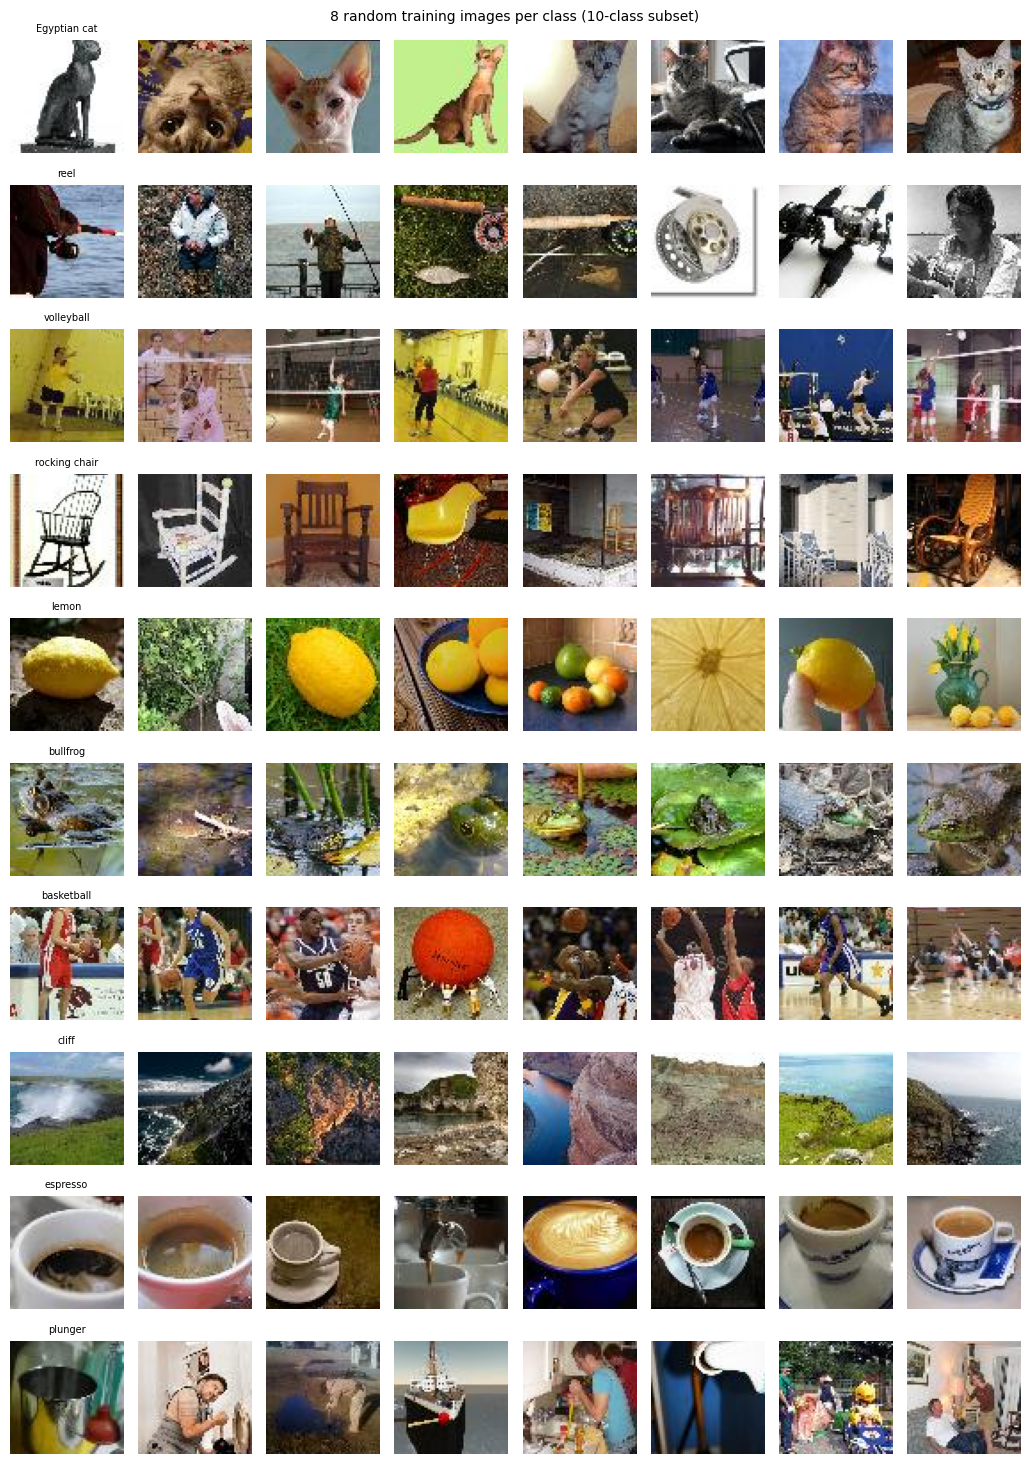

In [6]:
rng = np.random.default_rng(SEED)
subset_paths = {class_id: get_class_image_paths(train_dataset, class_id) for class_id in SUBSET_CLASSES}

images, titles = [], []
for class_id in SUBSET_CLASSES:
    picks = rng.choice(subset_paths[class_id], 8, replace=False)
    images.extend(picks)
    titles.extend([class_names[class_id]] + [""] * 7)

show_images(images, titles, ncols=8, title="8 random training images per class (10-class subset)")

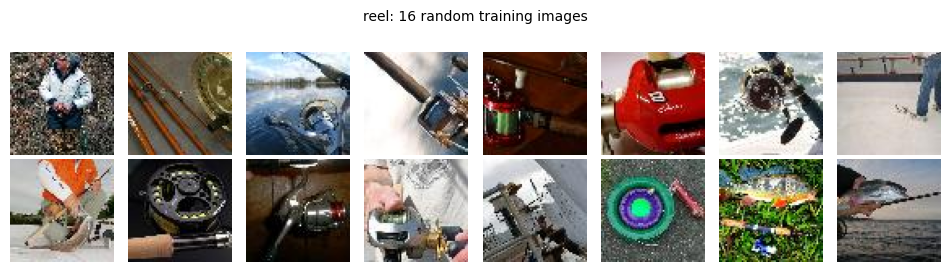

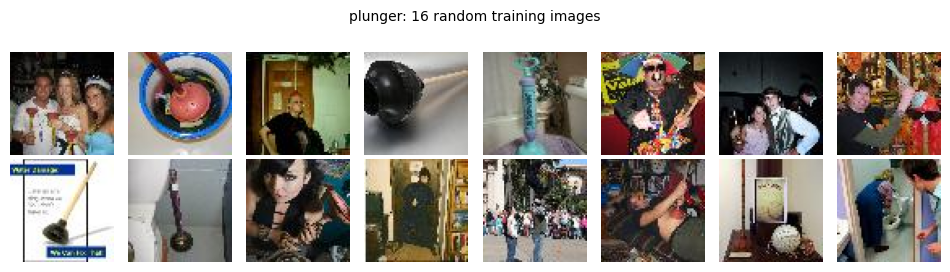

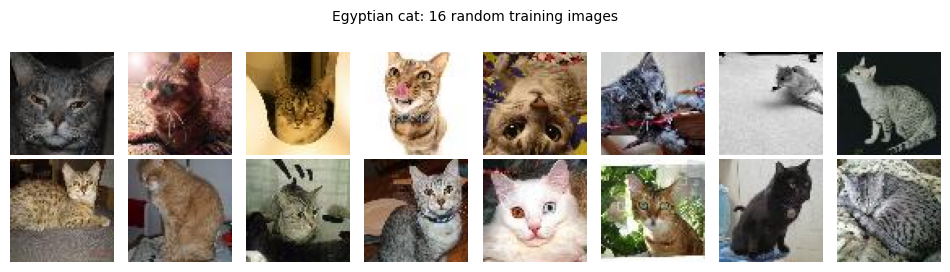

In [7]:
for class_name in ["reel", "plunger", "Egyptian cat"]:
    class_id = class_names.index(class_name)
    picks = rng.choice(subset_paths[class_id], 16, replace=False)
    show_images(picks, ncols=8, size=1.2, title=f"{class_name}: 16 random training images")

**Takeaway:** reel and plunger vary most (close-ups to small parts in scenes); the cat almost always fills the frame.

## 4 · Image format and unreadable files

In [8]:
BIT_COUNT = np.array([bin(value).count("1") for value in range(256)], dtype=np.uint8)  # set bits per byte (section 8)


def difference_hash(image):
    """64-bit difference hash: is each pixel brighter than its right neighbour, on a 9x8 grayscale thumbnail?"""
    small = np.asarray(image.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return np.packbits(small[:, 1:] > small[:, :-1])


def scan_images(dataset):
    """One pass over a split: image modes and sizes, unreadable files, content and difference hashes."""
    formats = Counter()
    unreadable = []
    content_hashes = []
    hashes = []

    for image_path, _ in dataset.samples:
        try:
            with Image.open(image_path) as image:
                image.load()
                formats[(image.mode, image.size)] += 1
                rgb = np.asarray(image.convert("RGB"))
                content_hashes.append(hashlib.sha1(rgb.tobytes()).hexdigest())  # identical pixels -> identical hash
                hashes.append(difference_hash(image))
        except OSError:
            unreadable.append(image_path)
            content_hashes.append(f"unreadable:{image_path}")
            hashes.append(np.zeros(8, dtype=np.uint8))

    return {
        "formats": formats,
        "unreadable": unreadable,
        "content_hashes": content_hashes,
        "hashes": np.stack(hashes),
    }

In [9]:
scans = {split_name: scan_images(dataset) for split_name, dataset in splits.items()}

rows = []
for split_name, scan in scans.items():
    modes = Counter()
    sizes = set()
    for (mode, (width, height)), count in scan["formats"].items():
        modes[mode] += count
        sizes.add(f"{width}x{height}")

    rows.append({
        "Split": split_name,
        "Readable Images": sum(modes.values()),
        "Image Sizes": ", ".join(sorted(sizes)),
        "RGB": modes["RGB"],
        "Grayscale": modes["L"],
        "Unreadable": len(scan["unreadable"]),
    })

pd.DataFrame(rows)

,Split,Readable Images,Image Sizes,RGB,Grayscale,Unreadable
0,Train,100000,64x64,98179,1821,0
1,Validation,10000,64x64,9832,168,0
2,Test,10000,64x64,9811,189,0


**Takeaway:** all 120,000 images open and are 64×64. About 1.8% are grayscale, so every transform starts with `convert_to_rgb`.

## 5 · Normalisation statistics

Per-channel mean and std, training images only.

In [10]:
def compute_normalization_statistics(dataset, class_ids=None, image_size=None):
    """Per-channel mean and std of the RGB pixels (0-1).

    class_ids: use only these classes (None = all classes).
    image_size: resize first, like the training transform (None = the native 64x64).
    """
    pixel_sum = np.zeros(3)
    pixel_square_sum = np.zeros(3)
    pixel_count = 0

    for image_path, target in dataset.samples:
        if class_ids is not None and target not in class_ids:
            continue

        image = Image.open(image_path).convert("RGB")
        if image_size is not None:
            image = image.resize((image_size, image_size), Image.BICUBIC)
        pixels = np.asarray(image, dtype=np.float64) / 255.0

        pixel_sum += pixels.sum(axis=(0, 1))
        pixel_square_sum += (pixels ** 2).sum(axis=(0, 1))
        pixel_count += pixels.shape[0] * pixels.shape[1]

    mean = pixel_sum / pixel_count
    std = np.sqrt(pixel_square_sum / pixel_count - mean ** 2)
    return mean, std

In [11]:
subset = set(SUBSET_CLASSES)
statistics = {
    "Train, 200 classes (64x64)": compute_normalization_statistics(train_dataset),
    # "Train, 10 classes (64x64)": compute_normalization_statistics(train_dataset, class_ids=subset),
}

rows = []
for name, (mean, std) in statistics.items():
    rows.append({
        "Statistics": name,
        "Mean R": mean[0], "Mean G": mean[1], "Mean B": mean[2],
        "Std R": std[0], "Std G": std[1], "Std B": std[2],
    })

train_mean, train_std = statistics["Train, 200 classes (64x64)"]
print("Values to use (training set, 200 classes):")
print("means =", [round(float(value), 4) for value in train_mean])
print("stds =", [round(float(value), 4) for value in train_std])
pd.DataFrame(rows).round(4)

Values to use (training set, 200 classes):
means = [0.4802, 0.4481, 0.3975]
stds = [0.2764, 0.2689, 0.2816]


,Statistics,Mean R,Mean G,Mean B,Std R,Std G,Std B
0,"Train, 200 classes (64x64)",0.4802,0.4481,0.3975,0.2764,0.2689,0.2816
1,"Train, 10 classes (64x64)",0.4897,0.4507,0.3800,0.2746,0.2684,0.2801


**Takeaway:** `means = [0.4802, 0.4481, 0.3975]`, `stds = [0.2764, 0.2689, 0.2816]` (in `src/utils/utils.py`), used for every run.

## 6 · Object size and position (bounding boxes)

Boxes are only analysed here, never used in training.

In [12]:
def object_size_table(dataset, boxes):
    """One row per image: object box, object size (% of image side), size group and box centre."""
    rows = []
    for image_path, target in dataset.samples:
        box = boxes[image_path.name]
        x0, y0, x1, y1 = box
        object_size = get_object_size(box)

        rows.append({
            "Path": image_path,
            "Label": target,
            "Box": box,
            "Object Size (%)": object_size,
            "Size Group": get_size_group(object_size),
            "Centre X": (x0 + x1 + 1) / 2,
            "Centre Y": (y0 + y1 + 1) / 2,
        })

    return pd.DataFrame(rows)


train_objects = object_size_table(train_dataset, load_boxes("train"))
val_objects = object_size_table(val_dataset, load_boxes("val"))
train_subset_objects = train_objects[train_objects["Label"] < NUM_SUBSET_CLASSES]
val_subset_objects = val_objects[val_objects["Label"] < NUM_SUBSET_CLASSES]

pd.DataFrame({
    "Train % (200 classes)": train_objects["Size Group"].value_counts(normalize=True) * 100,
    "Validation % (200 classes)": val_objects["Size Group"].value_counts(normalize=True) * 100,
    "Validation Images (10 classes)": val_subset_objects["Size Group"].value_counts(),
}).loc[SIZE_GROUPS].round(1)

,Train % (200 classes),Validation % (200 classes),Validation Images (10 classes)
Size Group,,,
Small (<40%),10.4,10.6,155
Medium (40-75%),22.1,22.2,121
Large (>=75%),67.5,67.2,224


In [13]:
def per_class_size_summary(objects):
    """Share of small / medium / large objects per class, the median object size and its spread (std)."""
    rows = []
    for class_id, class_objects in objects.groupby("Label"):
        sizes = class_objects["Object Size (%)"]
        groups = class_objects["Size Group"].value_counts(normalize=True) * 100

        row = {"Class": class_names[class_id]}
        for group in SIZE_GROUPS:
            row[f"{group} %"] = round(groups.get(group, 0.0))
        row["Median Size (%)"] = round(sizes.median())
        row["Size Spread (std)"] = round(sizes.std(ddof=0), 1)
        rows.append(row)

    return pd.DataFrame(rows)


per_class_size_summary(train_subset_objects)

,Class,Small (<40%) %,Medium (40-75%) %,Large (>=75%) %,Median Size (%),Size Spread (std)
0,Egyptian cat,0,9,90,99,12.0
1,reel,34,26,40,58,32.4
2,volleyball,97,2,1,12,12.0
3,rocking chair,1,14,84,96,15.8
4,lemon,15,39,46,70,24.7
5,bullfrog,4,23,73,88,18.9
6,basketball,90,5,5,19,18.4
7,cliff,4,15,81,100,19.9
8,espresso,8,40,52,75,21.9
9,plunger,30,42,27,55,25.8


In [14]:
def small_object_share(sizes):
    return (sizes < 40).mean() * 100


small_share = train_objects.groupby("Label")["Object Size (%)"].apply(small_object_share).sort_values(ascending=False)
print("Most small objects (200 classes):", [f"{class_names[c]} {share:.0f}%" for c, share in small_share.head(5).items()])
print("Fewest small objects:", [f"{class_names[c]} {share:.0f}%" for c, share in small_share.tail(5).items()])

Most small objects (200 classes): ['volleyball 97%', 'basketball 90%', 'rugby ball 89%', 'bow tie 70%', 'snorkel 62%']
Fewest small objects: ['pizza 0%', 'convertible 0%', 'barbershop 0%', 'dugong 0%', 'chest 0%']


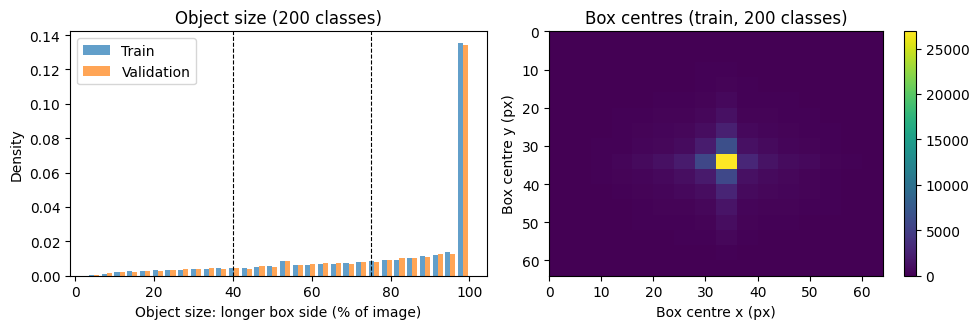

In [15]:
fig, (ax_size, ax_centre) = plt.subplots(1, 2, figsize=(10, 3.4))

ax_size.hist([train_objects["Object Size (%)"], val_objects["Object Size (%)"]], bins=30, density=True, label=["Train", "Validation"], alpha=0.7)
for threshold in (40, 75):
    ax_size.axvline(threshold, color="black", linestyle="--", linewidth=0.8)
ax_size.set(xlabel="Object size: longer box side (% of image)", ylabel="Density", title="Object size (200 classes)")
ax_size.legend()

heatmap = ax_centre.hist2d(train_objects["Centre X"], train_objects["Centre Y"], bins=16, range=[[0, 64], [0, 64]], cmap="viridis")
ax_centre.invert_yaxis()
ax_centre.set(xlabel="Box centre x (px)", ylabel="Box centre y (px)", title="Box centres (train, 200 classes)")
fig.colorbar(heatmap[3], ax=ax_centre)

plt.tight_layout()
plt.show()

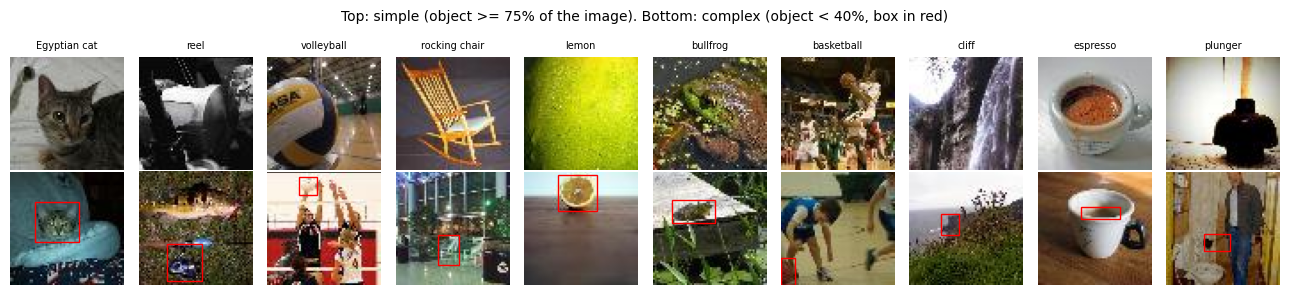

In [16]:
simple_rows, complex_rows = [], []
for class_id in SUBSET_CLASSES:
    class_objects = train_subset_objects[train_subset_objects["Label"] == class_id]
    simple_rows.append(class_objects[class_objects["Object Size (%)"] >= 75].sample(1, random_state=0).iloc[0])
    complex_rows.append(class_objects[class_objects["Object Size (%)"] < 40].sample(1, random_state=0).iloc[0])

images = [row["Path"] for row in simple_rows + complex_rows]
titles = [class_names[row["Label"]] for row in simple_rows] + [""] * NUM_SUBSET_CLASSES
boxes = [None] * NUM_SUBSET_CLASSES + [row["Box"] for row in complex_rows]
show_images(images, titles, boxes=boxes, ncols=NUM_SUBSET_CLASSES,
            title="Top: simple (object >= 75% of the image). Bottom: complex (object < 40%, box in red)")

**Takeaway:** most objects are large and centred (67% fill ≥ 75% of the image), but volleyball and basketball are almost always small (median 12% and 19% of the side), and reel and plunger vary most.

## 7 · Similar classes

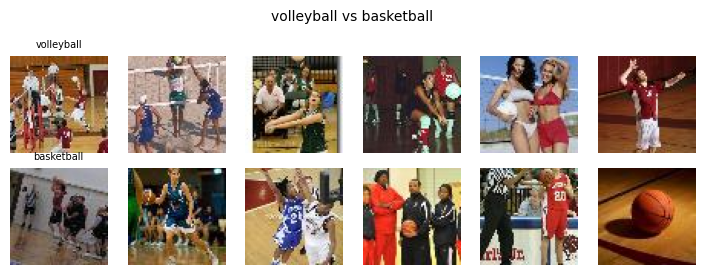

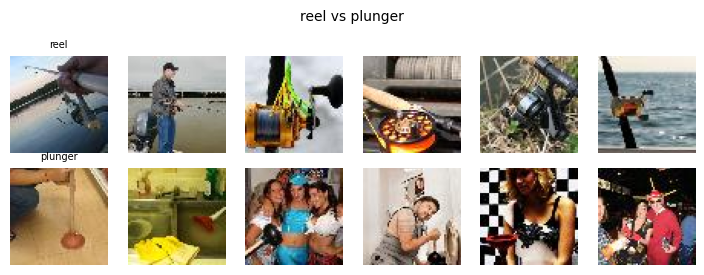

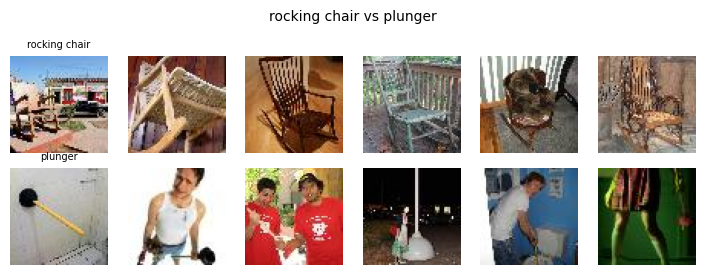

In [17]:
rng = np.random.default_rng(SEED)
similar_pairs = [("volleyball", "basketball"), ("reel", "plunger"), ("rocking chair", "plunger")]

for name_a, name_b in similar_pairs:
    picks_a = rng.choice(subset_paths[class_names.index(name_a)], 6, replace=False)
    picks_b = rng.choice(subset_paths[class_names.index(name_b)], 6, replace=False)
    titles = [name_a] + [""] * 5 + [name_b] + [""] * 5
    show_images(list(picks_a) + list(picks_b), titles, ncols=6, size=1.2, title=f"{name_a} vs {name_b}")

In [18]:
similar_groups = {
    "Dogs": ["German shepherd", "Labrador retriever", "golden retriever", "Yorkshire terrier", "Chihuahua", "standard poodle"],
    "Cats": ["Egyptian cat", "tabby", "Persian cat"],
    "Vehicles": ["school bus", "moving van", "tractor", "police van", "limousine", "sports car", "beach wagon", "trolleybus", "convertible", "go-kart"],
    "Balls": ["volleyball", "basketball", "rugby ball"],
}

rows = []
for group_name, members in similar_groups.items():
    labels = sorted(class_names.index(name) for name in members)
    row = {"Group": group_name}
    for num_classes in (10, 50, 100, 200):
        row[f"In First {num_classes}"] = sum(label < num_classes for label in labels)
    row["Classes (Label)"] = ", ".join(f"{class_names[label]} ({label})" for label in labels)
    rows.append(row)

pd.DataFrame(rows)

,Group,In First 10,In First 50,In First 100,In First 200,Classes (Label)
0,Dogs,0,2,3,6,"German shepherd (11), Labrador retriever (39),..."
1,Cats,1,1,2,3,"Egyptian cat (0), tabby (66), Persian cat (131)"
2,Vehicles,0,1,4,10,"school bus (15), moving van (64), tractor (75)..."
3,Balls,2,2,2,3,"volleyball (2), basketball (6), rugby ball (128)"


**Takeaway:** similar classes share the scene (volleyball / basketball) or the shape (reel / plunger / rocking chair). The full 200 have 6 dog breeds, 3 cats, 10 vehicles and 3 balls.

## 8 · Duplicates and label conflicts (all splits)

Exact duplicates by content hash; near duplicates by difference hash (distance ≤ 4).

In [19]:
SPLIT_ORDER = ["Train", "Validation", "Test"]


def exact_duplicate_groups(scans, splits):
    """Groups of images with identical pixel content, across all splits: [(split, image path, label), ...]."""
    images_by_content = {}
    for split_name, scan in scans.items():
        samples = splits[split_name].samples
        for (image_path, target), content_hash in zip(samples, scan["content_hashes"]):
            images_by_content.setdefault(content_hash, []).append((split_name, image_path, target))

    groups = []
    for images in images_by_content.values():
        if len(images) > 1:
            groups.append(images)
    return groups


def get_duplicate_type(group):
    split_names = sorted({split_name for split_name, _, _ in group}, key=SPLIT_ORDER.index)
    if len(split_names) == 1:
        return f"Within {split_names[0]}"
    return " ↔ ".join(split_names)


def has_label_conflict(group):
    labels = {target for _, _, target in group if target >= 0}  # test images have no label (-1)
    return len(labels) > 1


def touches_subset(group):
    return any(0 <= target < NUM_SUBSET_CLASSES for _, _, target in group)


def is_same_image(path_a, path_b, max_pixel_difference=0.02):
    return np.abs(load_pixels(path_a) - load_pixels(path_b)).mean() < max_pixel_difference


def hash_distance(hashes_a, hashes_b):
    """Number of different bits between every pair of hashes (rows of a against rows of b)."""
    different_bits = hashes_a[:, None, :] ^ hashes_b[None, :, :]
    return BIT_COUNT[different_bits].sum(axis=-1)

In [20]:
duplicate_groups = exact_duplicate_groups(scans, splits)

rows = []
for group in duplicate_groups:
    rows.append({
        "Duplicate Type": get_duplicate_type(group),
        "Label Conflict": has_label_conflict(group),
        "Images": len(group),
        "Touches 10-Class Subset": touches_subset(group),
    })
duplicate_summary = pd.DataFrame(rows)

total_images = sum(len(dataset) for dataset in splits.values())
print(f"{len(duplicate_groups)} groups of identical images: {duplicate_summary['Images'].sum()} of {total_images:,} images")

duplicate_summary.groupby(["Duplicate Type", "Label Conflict"]).agg(
    Groups=("Images", "size"),
    Images=("Images", "sum"),
    Touching_Subset=("Touches 10-Class Subset", "sum"),
).rename(columns={"Touching_Subset": "Groups Touching 10-Class Subset"})

39 groups of identical images: 78 of 120,000 images


,,Groups,Images,Groups Touching 10-Class Subset
Duplicate Type,Label Conflict,,,
Train ↔ Test,False,9,18,1
Train ↔ Validation,True,7,14,1
Validation ↔ Test,False,1,2,0
Within Test,False,2,4,0
Within Train,True,20,40,4


Groups that touch the 10-class subset:
  Train n07749582_144.JPEG (lemon)  =  Train n07747607_32.JPEG (orange)
  Train n07749582_168.JPEG (lemon)  =  Train n07747607_339.JPEG (orange)
  Train n07749582_396.JPEG (lemon)  =  Train n07753592_163.JPEG (banana)
  Train n07749582_415.JPEG (lemon)  =  Train n07753592_10.JPEG (banana)
  Train n01641577_321.JPEG (bullfrog)  =  Test test_9295.JPEG (no label)
  Train n03976657_298.JPEG (pole)  =  Validation val_8670.JPEG (reel)


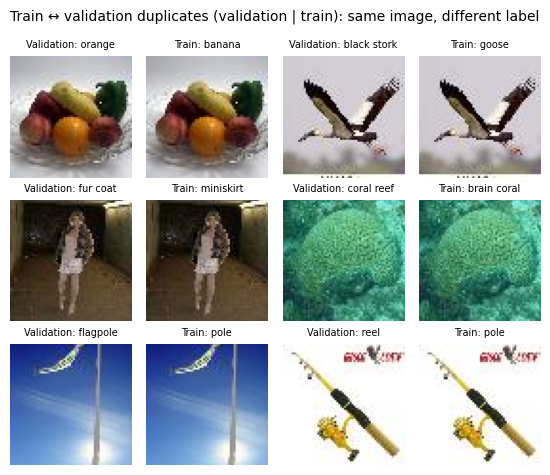

In [21]:
print("Groups that touch the 10-class subset:")
for group in duplicate_groups:
    if not touches_subset(group):
        continue
    parts = []
    for split_name, image_path, target in group:
        label = class_names[target] if target >= 0 else "no label"
        parts.append(f"{split_name} {image_path.name} ({label})")
    print("  " + "  =  ".join(parts))

images, titles = [], []
for group in duplicate_groups:
    if get_duplicate_type(group) == "Train ↔ Validation":
        val_items = [item for item in group if item[0] == "Validation"]
        train_items = [item for item in group if item[0] == "Train"]
        for split_name, image_path, target in val_items + train_items:
            images.append(image_path)
            titles.append(f"{split_name}: {class_names[target]}")
show_images(images[:12], titles[:12], ncols=4, size=1.4, title="Train ↔ validation duplicates (validation | train): same image, different label")

In [22]:
# near duplicates inside the 10-class subset (resized or re-saved copies that are not pixel-identical)
train_hashes = scans["Train"]["hashes"]
val_hashes = scans["Validation"]["hashes"]
subset_val_ids = [index for index, target in enumerate(val_dataset.targets) if target < NUM_SUBSET_CLASSES]
subset_train_ids = [index for index, target in enumerate(train_dataset.targets) if target < NUM_SUBSET_CLASSES]
distances = hash_distance(val_hashes[subset_val_ids], train_hashes[subset_train_ids])

near_candidates = []
for a, b in zip(*np.nonzero(distances <= 4)):
    near_candidates.append((subset_val_ids[a], subset_train_ids[b]))

near_duplicates = []
for val_index, train_index in near_candidates:
    if is_same_image(val_dataset.samples[val_index][0], train_dataset.samples[train_index][0]):
        near_duplicates.append((val_index, train_index))

print(f"10-class subset, validation vs train: {len(near_candidates)} near-duplicate candidates, {len(near_duplicates)} confirmed")

10-class subset, validation vs train: 8 near-duplicate candidates, 0 confirmed


**Takeaway:** 39 groups of identical images (78 of 120,000); 7 train–val pairs, all with different labels. Nothing leaks with the same label, so all images are kept (54 conflicting labels = 0.05% label noise).

## 9 · MixUp and CutMix

MixUp λ ~ Beta(0.2, 0.2); CutMix λ ~ Beta(1, 1).

In [23]:
def random_cutmix_box(lam, rng, image_size=64):
    """CutMix patch with area (1 - lam) at a random centre, clipped to the image (half-open box)."""
    patch_size = int(image_size * np.sqrt(1 - lam))
    centre_x = rng.integers(0, image_size)
    centre_y = rng.integers(0, image_size)

    x0 = np.clip(centre_x - patch_size // 2, 0, image_size)
    x1 = np.clip(centre_x + patch_size // 2, 0, image_size)
    y0 = np.clip(centre_y - patch_size // 2, 0, image_size)
    y1 = np.clip(centre_y + patch_size // 2, 0, image_size)
    return int(x0), int(y0), int(x1), int(y1)


def mixup(image_a, image_b, lam):
    """Blend two images; label weight of A = lam."""
    return lam * image_a + (1 - lam) * image_b, lam


def cutmix(image_a, image_b, lam, rng):
    """Paste a patch of B into A; label weight of A = the area of A that is still visible."""
    x0, y0, x1, y1 = random_cutmix_box(lam, rng)
    mixed = image_a.copy()
    mixed[y0:y1, x0:x1] = image_b[y0:y1, x0:x1]
    weight_a = 1 - (x1 - x0) * (y1 - y0) / (mixed.shape[0] * mixed.shape[1])
    return mixed, weight_a

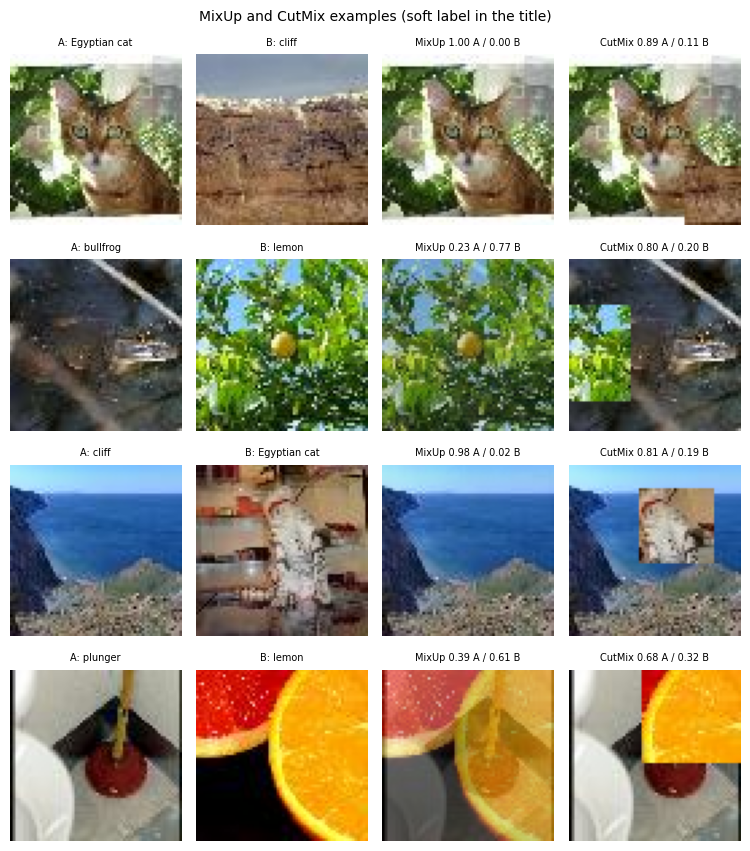

In [24]:
rng = np.random.default_rng(SEED)
images, titles = [], []

for _ in range(4):
    class_a, class_b = rng.choice(SUBSET_CLASSES, 2, replace=False)
    image_a = load_pixels(rng.choice(subset_paths[class_a]))
    image_b = load_pixels(rng.choice(subset_paths[class_b]))

    mixup_image, mixup_weight = mixup(image_a, image_b, rng.beta(0.2, 0.2))
    cutmix_image, cutmix_weight = cutmix(image_a, image_b, rng.beta(1.0, 1.0), rng)

    images.extend([image_a, image_b, mixup_image, cutmix_image])
    titles.extend([
        f"A: {class_names[class_a]}",
        f"B: {class_names[class_b]}",
        f"MixUp {mixup_weight:.2f} A / {1 - mixup_weight:.2f} B",
        f"CutMix {cutmix_weight:.2f} A / {1 - cutmix_weight:.2f} B",
    ])

show_images(images, titles, ncols=4, size=1.9, title="MixUp and CutMix examples (soft label in the title)")

In [25]:
def cutmix_object_coverage(objects, draws_per_image=10, seed=SEED):
    """CutMix on image A: share of A's object box hidden by the pasted patch, and the label weight A keeps."""
    rng = np.random.default_rng(seed)
    rows = []

    for box, size_group in zip(objects["Box"], objects["Size Group"]):
        x0, y0, x1, y1 = box
        object_area = (x1 - x0 + 1) * (y1 - y0 + 1)

        for _ in range(draws_per_image):
            lam = rng.beta(1.0, 1.0)
            patch_x0, patch_y0, patch_x1, patch_y1 = random_cutmix_box(lam, rng)

            overlap_width = max(0, min(patch_x1, x1 + 1) - max(patch_x0, x0))
            overlap_height = max(0, min(patch_y1, y1 + 1) - max(patch_y0, y0))
            hidden = overlap_width * overlap_height / object_area
            weight_a = 1 - (patch_x1 - patch_x0) * (patch_y1 - patch_y0) / 64 ** 2

            rows.append({
                "Size Group": size_group,
                "Object Hidden": hidden,
                "Mostly Hidden": hidden >= 0.5,
                "Misleading Label": hidden >= 0.5 and weight_a >= 0.5,
            })

    return pd.DataFrame(rows)


coverage = cutmix_object_coverage(train_subset_objects)
by_group = coverage.groupby("Size Group")

summary = pd.DataFrame({
    "Object Hidden (%)": by_group["Object Hidden"].mean() * 100,
    "Object Mostly Hidden (%)": by_group["Mostly Hidden"].mean() * 100,
    "Misleading Label (%)": by_group["Misleading Label"].mean() * 100,
}).loc[SIZE_GROUPS].round(1)

mixup_weights = np.random.default_rng(SEED).beta(0.2, 0.2, 100_000)
really_mixed = ((mixup_weights > 0.1) & (mixup_weights < 0.9)).mean()
print(f"MixUp, Beta(0.2, 0.2): {really_mixed:.0%} of draws mix the two images by more than 10%")
print("Misleading label = at least half of A's object is hidden, but A still gets a label weight of 0.5 or more")
summary

MixUp, Beta(0.2, 0.2): 33% of draws mix the two images by more than 10%
Misleading label = at least half of A's object is hidden, but A still gets a label weight of 0.5 or more


,Object Hidden (%),Object Mostly Hidden (%),Misleading Label (%)
Size Group,,,
Small (<40%),33.6,34.0,22.7
Medium (40-75%),36.0,33.2,19.9
Large (>=75%),33.2,23.1,7.9


**Takeaway:** most MixUp samples are nearly unmixed (only 33% mix > 10%); CutMix often hides small objects but keeps their label, so the final runs use ResizeMix instead.

## 10 · Object colour vs background colour

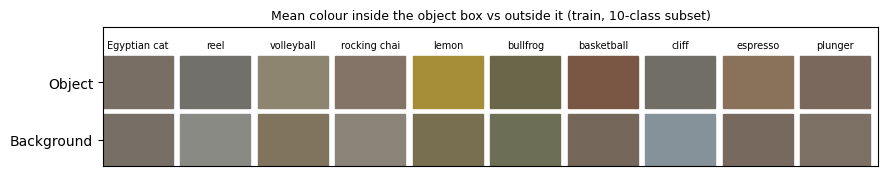

In [26]:
object_colour, background_colour = {}, {}

for class_id in SUBSET_CLASSES:
    class_objects = train_subset_objects[train_subset_objects["Label"] == class_id]
    object_means, background_means = [], []

    for image_path, box in zip(class_objects["Path"], class_objects["Box"]):
        pixels = load_pixels(image_path)
        x0, y0, x1, y1 = box
        inside = np.zeros(pixels.shape[:2], dtype=bool)
        inside[y0:y1 + 1, x0:x1 + 1] = True

        object_means.append(pixels[inside].mean(axis=0))
        if (~inside).sum() > 64:  # skip boxes that fill the whole image
            background_means.append(pixels[~inside].mean(axis=0))

    object_colour[class_id] = np.mean(object_means, axis=0)
    background_colour[class_id] = np.mean(background_means, axis=0)

fig, ax = plt.subplots(figsize=(10, 1.8))
for position, class_id in enumerate(SUBSET_CLASSES):
    ax.add_patch(Rectangle((position, 1), 0.9, 0.9, color=object_colour[class_id]))
    ax.add_patch(Rectangle((position, 0), 0.9, 0.9, color=background_colour[class_id]))
    ax.text(position + 0.45, 2.05, class_names[class_id][:12], ha="center", fontsize=7)

ax.set(xlim=(0, NUM_SUBSET_CLASSES), ylim=(0, 2.4), yticks=[0.45, 1.45], yticklabels=["Background", "Object"], xticks=[])
ax.set_title("Mean colour inside the object box vs outside it (train, 10-class subset)", fontsize=9)
plt.show()

**Takeaway:** only lemon and basketball differ clearly in colour from their background, so they are most exposed to colour shortcuts.

## 11 · Data decisions

| Item | Decision |
|---|---|
| Dataset | Original Tiny ImageNet-200, every image kept |
| Evaluation set | Official validation set |
| Class subset | First classes in `wnids.txt` (nested) |
| Grayscale | Converted to RGB |
| Corrupted files | None |
| Normalisation | Training-set mean / std |
| Input size | 64×64 |
| Bounding boxes | Not used in training |
| Duplicates | Kept: no same-label leakage |